<a href="https://colab.research.google.com/github/disiree31-abel/cs82a-portfolio/blob/main/Module_7_Lab_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score

# Load the tips dataset
df = pd.read_csv("tips.csv")

# Features and target
X = df[["total_bill"]]
y = df["tip"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

print("Dataset shape:", df.shape)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Dataset shape: (244, 7)
Training rows: 170
Testing rows: 74


We hold out 30% of the data to test how well the model predicts information it has never seen before. This helps us understand whether the model learned a useful pattern instead of just memorizing the training data. It also gives us a more honest idea of how the model might perform on new data.

In [2]:

# Create and train the regression model
regression_model = LinearRegression()
regression_model.fit(X_train, y_train)

# Print the slope and intercept
slope = regression_model.coef_[0]
intercept = regression_model.intercept_

print("Slope:", slope)
print("Intercept:", intercept)
print("Test R-squared:", regression_model.score(X_test, y_test))


Slope: 0.10889370921420226
Intercept: 0.8769576391532707
Test R-squared: 0.4291782688312412


The slope is approximately 0.109. This means that for every additional dollar on the total bill, the predicted tip increases by about 11 cents.

The intercept is approximately 0.877. This means the model predicts a tip of about 88 cents when the bill is 0 dollars.

The test R-squared is approximately 0.429. This means the model explains about 42.9 percent of the variation in tips on the test data.

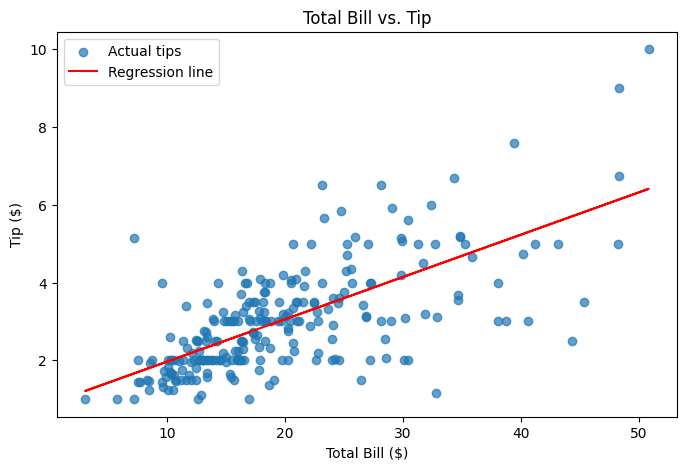

In [3]:

y_pred = regression_model.predict(X)

plt.figure(figsize=(8, 5))
plt.scatter(df["total_bill"], df["tip"], alpha=0.7, label="Actual tips")
plt.plot(df["total_bill"], y_pred, color="red", label="Regression line")

plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.title("Total Bill vs. Tip")
plt.legend()
plt.show()


In [4]:

iris = load_iris(as_frame=True)

X_iris = iris.data
y_iris = iris.target

X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris,
    y_iris,
    test_size=0.30,
    random_state=42,
    stratify=y_iris
)

print("Total flowers:", len(X_iris))
print("Training flowers:", len(X_train_iris))
print("Testing flowers:", len(X_test_iris))
print(X_iris.head())


Total flowers: 150
Training flowers: 105
Testing flowers: 45
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [5]:

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_iris, y_train_iris)

knn_predictions = knn.predict(X_test_iris)
knn_accuracy = accuracy_score(y_test_iris, knn_predictions)

print("kNN test accuracy:", knn_accuracy)
print(f"kNN test accuracy: {knn_accuracy:.2%}")


kNN test accuracy: 0.9777777777777777
kNN test accuracy: 97.78%


Shallow tree test accuracy: 97.78%


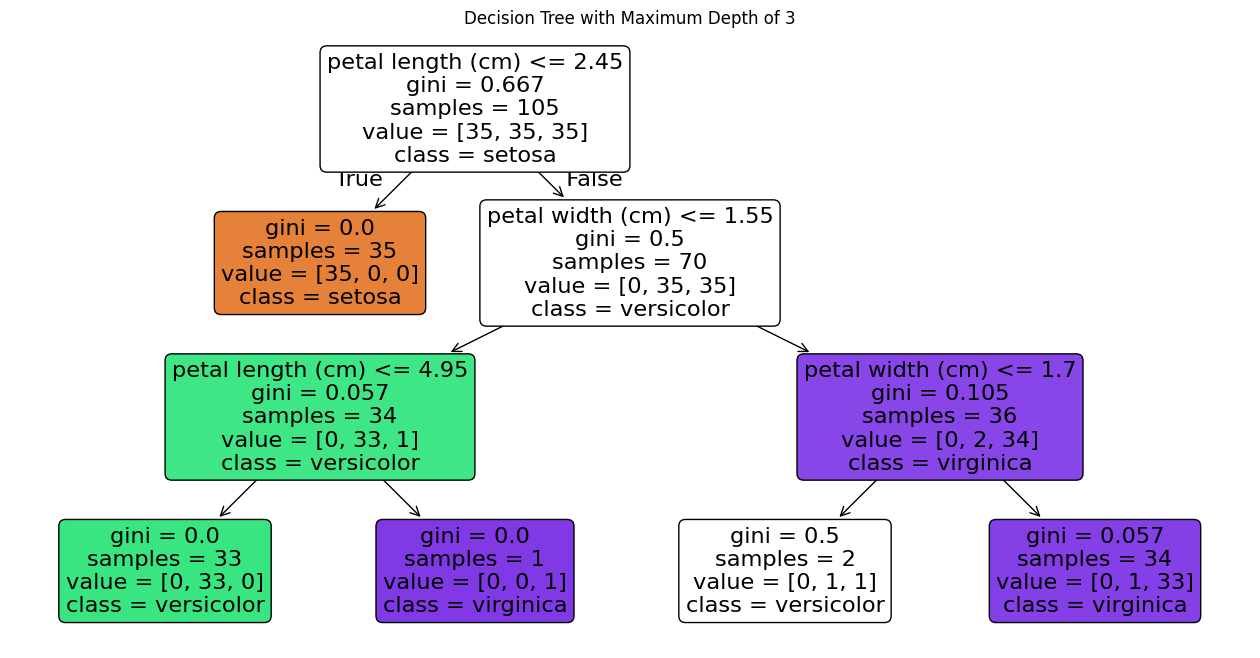

Root feature: petal length (cm)
Root threshold: 2.449999988079071


In [6]:

shallow_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
shallow_tree.fit(X_train_iris, y_train_iris)

shallow_accuracy = shallow_tree.score(X_test_iris, y_test_iris)

print(f"Shallow tree test accuracy: {shallow_accuracy:.2%}")

plt.figure(figsize=(16, 8))
plot_tree(
    shallow_tree,
    feature_names=list(X_iris.columns),
    class_names=list(iris.target_names),
    filled=True,
    rounded=True
)
plt.title("Decision Tree with Maximum Depth of 3")
plt.show()

root_index = shallow_tree.tree_.feature[0]
root_feature = X_iris.columns[root_index]
root_threshold = shallow_tree.tree_.threshold[0]

print("Root feature:", root_feature)
print("Root threshold:", root_threshold)


The decision tree uses petal measurements to help classify the flowers. At the first split, it compares the selected petal measurement to a threshold and separates the flowers into groups. These splits help the model predict the most likely species.

In [7]:

unlimited_tree = DecisionTreeClassifier(random_state=42)
unlimited_tree.fit(X_train_iris, y_train_iris)

comparison = pd.DataFrame({
    "Model": ["Shallow Tree", "Unlimited Tree"],
    "Training Accuracy": [
        shallow_tree.score(X_train_iris, y_train_iris),
        unlimited_tree.score(X_train_iris, y_train_iris)
    ],
    "Test Accuracy": [
        shallow_tree.score(X_test_iris, y_test_iris),
        unlimited_tree.score(X_test_iris, y_test_iris)
    ]
})

print(comparison.round(3).to_string(index=False))


         Model  Training Accuracy  Test Accuracy
  Shallow Tree              0.981          0.978
Unlimited Tree              1.000          0.933


The unlimited decision tree can memorize the training data and reach 100% training accuracy. However, its test accuracy may be lower because it does not generalize as well to new data. The shallow tree limits its complexity and may perform better on unseen flowers.

In [8]:

new_flower = pd.DataFrame([{
    "sepal length (cm)": 5.1,
    "sepal width (cm)": 3.5,
    "petal length (cm)": 1.4,
    "petal width (cm)": 0.2
}])

prediction = knn.predict(new_flower)
predicted_species = iris.target_names[prediction[0]]

print("Predicted species:", predicted_species)


Predicted species: setosa


In [9]:

print(f"kNN test accuracy: {knn.score(X_test_iris, y_test_iris):.2%}")
print(f"Shallow tree test accuracy: {shallow_tree.score(X_test_iris, y_test_iris):.2%}")
print(f"Unlimited tree test accuracy: {unlimited_tree.score(X_test_iris, y_test_iris):.2%}")
print("Predicted species:", predicted_species)


kNN test accuracy: 97.78%
Shallow tree test accuracy: 97.78%
Unlimited tree test accuracy: 93.33%
Predicted species: setosa


In this lab, I used linear regression to predict tips based on the total bill and used kNN and decision trees to predict iris flower species. The regression model showed that tips generally increase as the total bill increases, with each additional dollar adding about $0.11 to the predicted tip. I would choose the classification model with the highest test accuracy because it performed best on flowers it had not seen during training. However, the model could make incorrect predictions if a flower has unusual measurements or shares similar characteristics with another species. If this model were used to make predictions about people, one risk would be bias if the training data did not fairly represent different groups. Overall, this lab helped me understand why testing a model on new data is important for seeing how well it can make predictions in real situations.